<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_MASTER_PIPELINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS 2.0 — Master pipeline

**One notebook for the whole workflow:** environment → data acquisition → validation → preprocessing → geological EDA repair → spatial splits → feature store → baselines → research experiments → discovery evaluation → ensembling → full inference → submission → reports.

Every stage **checks Drive first, reuses valid outputs, builds only what is missing, saves to Google Drive immediately and records provenance**. Re-running any cell after a disconnect resumes where it stopped.

```
bootstrap → raw_data → native_grid ─┬─ geological_eda → segment_attributes ─┐
                                    ├─ spatial_folds ───────────────────────┼─→ feature_store ─→ baselines ─→ discovery_validation ─→ ensemble
                                    ├─ discovery_splits ────────────────────┘        │               └─→ advanced_models ──┘
                                    └─ dem_inventory ─→ dem_pilot (needs feature_store)   └─→ full_inference ─→ submission
                                                                                     reports (always last)
```

| decision | meaning |
|---|---|
| `SKIP_CACHED` | outputs exist, pass content checks, and were made under this configuration (or are pre-existing artifacts, adopted with provenance) |
| `BUILD` / `RESUME` | outputs missing / partial: built, or resumed from completed units and checkpoints |
| `INCOMPATIBLE` | outputs exist but differ from the configuration: **never overwritten**; changed protocols get a new versioned folder |
| `BLOCKED` | a prerequisite is missing: the message names it and the recovery action |
| `DISABLED` | switched off in `CONFIG` (expensive stages are off by default) |

**Safety:** default mode `RESUME`; GPU training, DEM tile downloads, full inference and submission export are off until enabled below. Nothing is ever deleted on Drive, nothing is uploaded to the competition, no URL or token is written to disk. Pseudo-discovery scores are local-protocol numbers, never leaderboard scores.

Guide: `docs/MASTER_COLAB_GUIDE.md` · dependencies: `docs/PIPELINE_DEPENDENCIES.md` · recovery: `docs/ARTIFACT_RECOVERY.md`.

## 1. Configuration (control panel)

Edit, then run the cells top to bottom (or use the one-shot run in section 6). Keys are validated: a typo raises an error naming the closest valid key.

**Modes:** `SETUP_ONLY` (verify environment and existing data, no downloads) · `PREPARE_DATA` (download / preprocess missing data, EDA repair, splits, features) · `BASELINES` (+ restore / train baselines and the scoreboard) · `ADVANCED_RESEARCH` (+ PU, geometry, GeoStructureNet experiments) · `FULL_PIPELINE` (every enabled stage) · `RESUME` (continue from saved state; default) · `SUBMISSION_ONLY` (promoted model → GeoTIFF; prerequisites validated, not rebuilt).

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                                   # pin a commit SHA for reproducible experiments
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'run_mode': 'RESUME',
    'download_missing': True,                        # only files absent / invalid on Drive AND locally
    'rebuild_missing': True,

    'run_eda': True,                                 # minimal Phase-1 rebuild if outputs/eda is missing (CPU)
    'run_baselines': True,                           # scan / verify baselines (cheap)
    'train_baselines': [],                           # e.g. ['B0_lineament', 'G1', 'G3']; GPU: 'CNN_A_dti', 'DL00_CNN_B_dti', 'P4_B_gated'
    'run_advanced_features': True,
    'run_advanced_models': False,                    # GPU research experiments (opt-in)
    'advanced_experiments': ['b0_reference', 'b1_bg_weight', 'b2_nnpu_p010', 'c1_geometry_heads', 'e1_gsn_parity'],
    'run_dem_pilot': False,
    'run_scoreboard': True,
    'run_ensemble': True,
    'run_full_inference': False,                     # needs a PROMOTED model (manual decision)
    'run_submission': False,                         # writes GeoTIFFs; never uploads

    'use_gpu': True,
    'max_stage_minutes': 0,                          # e.g. 200 on free tier: clean, resumable stop
    'save_figures': True,
    'save_intermediate': True,
    'seed': 2026,
}

DEM_CONFIG = {
    'enabled': False,
    'mode': 'pilot',                                 # 'pilot' | 'inventory_only' (never the full collection)
    'download': False,                               # explicit approval, after reading the storage estimate
    'pilot_tiles': 24,                               # spatially balanced pilot (f1_dem_pilot.yaml)
    'max_tiles': 30,
    'max_gib': 15.0,
    'download_only_intersecting': True,
    'compute_morphology': True,                      # 1 m morphology before aggregation
    'aggregate_to_100m': True,
}

## 2–4. Google Drive, GitHub installation, package import

Idempotent: mounts Drive, clones (or updates) the repository at `CONFIG['ref']`, installs `gems-fault-discovery` in editable mode. A private repository is cloned with a token from Colab *Secrets* (`GITHUB_TOKEN`); the token is never printed or stored. PyTorch is **not** reinstalled (Colab's CUDA build is the right one).

In [2]:
import os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
token = ''
try:
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN') or ''
except Exception:
    pass
url = f"https://{token}@github.com/{CONFIG['repo']}.git" if token else f"https://github.com/{CONFIG['repo']}.git"
if not os.path.exists(f'{CODE}/.git'):
    subprocess.run(['git', 'clone', '-q', url, CODE], check=True)
subprocess.run(['git', '-C', CODE, 'fetch', '-q', 'origin'], check=True)
subprocess.run(['git', '-C', CODE, 'checkout', '-q', CONFIG['ref']], check=True)
# a branch ref follows origin (fast-forward only); a commit SHA has no origin/<sha> and stays pinned
subprocess.run(['git', '-C', CODE, 'merge', '-q', '--ff-only', 'origin/' + CONFIG['ref']], check=False, capture_output=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)                          # editable install is not visible to a running kernel
del token, url
print('commit', subprocess.run(['git', '-C', CODE, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip())

Mounted at /content/drive
commit 8ac074d442c5f16a50937595f568c26aca544b23


### Fresh download URLs (only when a raw file is missing on Drive)

DrivenData links are personal and **expire**. Preferred: Colab *Secrets* (key icon, enable notebook access) named `GEMS_URL_FEATURES`, `GEMS_URL_FAULTS`, `GEMS_URL_SUBMISSION` (and optionally `GEMS_URL_DEM_JSON`). Alternative: set `ASK_FOR_URLS = True` to paste them here (hidden input). URLs live only in memory; the acquisition manifest stores only the host and a hash. Files already valid on Drive are never downloaded again.

In [3]:
URLS = {}
ASK_FOR_URLS = False
if ASK_FOR_URLS:
    from getpass import getpass
    for key in ('features', 'faults', 'submission', 'dem_json'):
        u = getpass(f'URL for {key} (Enter to skip): ').strip()
        if u:
            URLS[key] = u

from IPython.display import display
from gems_bench.pipeline import Pipeline
pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG, urls=URLS)
display(pipe.cfg.table())

,key,value
0,version,1
1,repo,"""mybenkhadda/GEMS---drivendata"""
2,ref,"""main"""
3,seed,2026
4,run_mode,"""RESUME"""
...,...,...
58,gpu.max_stage_minutes,0
59,gpu.overrides,{}
60,sync.push_after_stage,true
61,reports.save_figures,true


## 5. Environment and GPU verification

`torch.cuda.is_available()` is what counts (a CPU-only PyTorch is not GPU support). GPU stages stop with *Runtime → Change runtime type → GPU* when no GPU is attached. Batch size, precision (bf16 only on compute capability ≥ 8) and inference batch adapt to the GPU found; the effective batch, patch size and epochs never change.

In [4]:
pipe.step('bootstrap')
from gems_bench.training import gpu
g = pipe.pc.gpu()
print(g)
if CONFIG['use_gpu'] and not g.get('cuda'):
    print('No CUDA GPU in this runtime: GPU stages will stop with instructions. '
          'Runtime -> Change runtime type -> GPU, or set use_gpu=False.')
else:
    print('autoconfig (256 px, effective batch 16, 29 channels):',
          gpu.autoconfig(g, patch_px=256, effective_batch=16, n_channels=29))
display(__import__('pandas').read_csv('/content/gems_work/reports/pipeline/environment_report.csv'))

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
{'cuda': False, 'name': None, 'vram_gb': 0.0, 'capability': None, 'count': 0}
No CUDA GPU in this runtime: GPU stages will stop with instructions. Runtime -> Change runtime type -> GPU, or set use_gpu=False.


,key,value
0,package,gems-fault-discovery
1,version,0.5.0
2,git_commit,8ac074d442c5f16a50937595f568c26aca544b23
3,python,3.13.16
4,gpu,NaN
5,vram_gb,0.0
6,capability,NaN
7,torch,2.11.0+cpu
8,cuda,NaN
9,free_gb:/content,205.3


## 6. Persistent storage overview and execution plan

Read-only: validates what already exists **on Drive** and predicts each stage's action for the selected mode. Nothing is built here.

**One-shot alternative:** `pipe.run()` executes the whole configured mode in dependency order (the cells below run the same stages one section at a time, with displays).

In [5]:
display(pipe.graph())
plan = pipe.plan()
display(plan)
from gems_bench.pipeline.status import storage
display(storage(pipe.pc))

RUN_EVERYTHING_NOW = False                           # True = run the configured mode in one call
if RUN_EVERYTHING_NOW:
    display(pipe.run())

,stage,title,deps,soft_deps,resource,requirement,reuse,versioned,est
0,bootstrap,"Environment, Drive, workspace folders",,,light,regenerable,always_run,False,<1
1,raw_data,"Competition files: locate, validate, download ...",bootstrap,,network,raw_required,reuse_valid,False,1-10
2,native_grid,"Native 100 m grid, labels, template checks",raw_data,,cpu,regenerable,reuse_valid,False,1-2
3,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),native_grid,,cpu-heavy,regenerable,reuse_valid,False,15-45
4,segment_attributes,Native-grid segment ids + attributes,geological_eda,,cpu,regenerable,reuse_valid,False,2-5
5,spatial_folds,Geographic folds (Phase-2 protocol),native_grid,,cpu,regenerable,reuse_valid,True,1-3
6,discovery_splits,Pseudo-discovery fault-system splits,native_grid,,cpu,regenerable,reuse_valid,True,1-3
7,feature_store,"Feature store: compute once, reuse","segment_attributes, spatial_folds, discovery_s...",,cpu-heavy,regenerable,delegated,False,10-90
8,dem_inventory,USGS 1 m DEM inventory (metadata only),native_grid,,light,optional,reuse_valid,False,1
9,dem_pilot,"1 m DEM pilot: selection, download, morphology...","dem_inventory, feature_store",,network-heavy,optional,delegated,False,30-180


,stage,title,outputs,planned,last_status,last_origin,last_finished,resource,est_minutes,detail
0,bootstrap,"Environment, Drive, workspace folders",ok,SKIP_CACHED,done,built,2026-10-22T13:38:18,light,<1,bootstrap: ok (3 checks)
1,raw_data,"Competition files: locate, validate, download ...",ok,SKIP_CACHED,,,,network,1-10,raw_data: ok (3 checks)
2,native_grid,"Native 100 m grid, labels, template checks",missing,BUILD,,,,cpu,1-2,native_grid: missing - native_grid.json: missi...
3,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),missing,BUILD,,,,cpu-heavy,15-45,eda_minimal: missing - known_fault_segments.pa...
4,segment_attributes,Native-grid segment ids + attributes,missing,BUILD,,,,cpu,2-5,native_segments: missing - native_segment_ids....
5,spatial_folds,Geographic folds (Phase-2 protocol),ok,SKIP_CACHED,,,,cpu,1-3,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
6,discovery_splits,Pseudo-discovery fault-system splits,ok,SKIP_CACHED,,,,cpu,1-3,discovery:discovery_d3_link1km_s2026: ok (3 ch...
7,feature_store,"Feature store: compute once, reuse",missing,BUILD,,,,cpu-heavy,10-90,feature_store: missing - raw_mag_anom.npy: mis...
8,dem_inventory,USGS 1 m DEM inventory (metadata only),missing,BUILD,,,,light,1,dem_inventory: missing - dem_inventory.csv: mi...
9,dem_pilot,"1 m DEM pilot: selection, download, morphology...",missing,DISABLED (DEM pilot disabled (stages.run_dem_p...,,,,network-heavy,30-180,dem_pilot: missing - f1_dem_pilot__888c6e12:pr...


,root,path,free_gb,total_gb
0,local,/content/gems_work,205.3,225.8
1,drive,/content/drive/MyDrive/GEMS_2,195.0,225.8


## 7. Raw data inventory and one-time download

Per file: Drive (canonical path, then accepted alternates such as `data/raw/example_submission.tif`) → local disk → resumable download (`.partial`, HTTP Range, retries) → GeoTIFF / JSON validation → verified atomic copy to Drive → manifest. Downloads happen only for files that are missing or invalid in both places.

In [6]:
from gems_bench.data.acquisition import inventory
display(inventory({'drive': pipe.pc.drive, 'local': pipe.pc.local}))
pipe.step('raw_data')

,key,root,rel,canonical,status,reason,bytes,required
0,features,drive,data/raw/geodawn/gems-geodawn-numerical-featur...,True,ok,,418912844,True
1,faults,drive,data/raw/faults/existing_faults.tif,True,ok,,425830,True
2,submission,drive,data/raw/example_submission.tif,False,ok,,1599597,True
3,dem_json,drive,data/raw/tnm_items.json,False,ok,,145842,False


[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']


StageResult(stage='raw_data', decision='BUILD', outcome='DONE', validation='ok', reason='raw_data: ok (3 checks)', recovery='', seconds=12.284346520999975, summary={'files': {'features': 'staged_from_drive', 'faults': 'staged_from_drive', 'submission': 'staged_from_drive', 'dem_json': 'staged_from_drive'}, 'dem_json': '/content/gems_work/data/raw/dem_1m/tnm_urls.json'}, outputs=['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv'])

## 8. USGS 1 m DEM inventory (metadata only) and optional pilot

The inventory parses the URL JSON (`data/raw/tnm_items.json` is accepted and copied to `data/raw/dem_1m/tnm_urls.json`), identifies source projects, duplicate URLs, overlapping projects per tile, study-area intersection and the storage estimate, and writes a footprint GeoPackage and figure. **No tile is downloaded here.** The pilot (after the feature store, section 12) selects a spatially balanced subset and downloads it only with `DEM_CONFIG['download'] = True`.

In [7]:
pipe.step('dem_inventory')
import json, pathlib
est = pathlib.Path('/content/gems_work/data/raw/dem_1m/inventory/dem_storage_estimate.json')
if est.exists():
    print(json.dumps(json.loads(est.read_text()), indent=1))

[dem_inventory] BLOCKED: missing prerequisite(s): native_grid (not run)


## 9. Native geospatial data verification

100 m GeoDAWN grid (EPSG:32611), mapped-fault labels (value ≥ 1), valid footprint, submission template on the same grid. Recorded in `environment/pipeline/native_grid.json` with raw-file fingerprints, so a new data release is detected instead of silently mixed.

In [8]:
pipe.step('native_grid')
display(pipe.pc.data.summary())

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/native_grid.json', 'reports/pipeline/native_band_table.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/native_grid.json']
[native_grid] DONE: native_grid: ok (1 checks)
[native_grid] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/native_grid.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/native_band_table.csv']


,key,value
0,crs,EPSG:32611
1,height,3730
2,width,3292
3,pixel_m_x,100.0
4,pixel_m_y,100.0
5,n_bands,19
6,valid_frac,0.42070076454741206
7,valid_km2,51658.520000000004
8,label_px,60988
9,label_frac_of_valid,0.011787794152832872


## 10. Phase 1 EDA dependency repair

Only the EDA artifacts later phases actually read are regenerated (fault segments + archetypes, fused lineament maps, cross-modal orientation), with the same `gems_eda` functions and defaults as notebook 01, into `outputs/eda_rebuild/<version>/`. Each artifact group is installed into `outputs/eda/` **only if the whole group is absent** (no mixing with, or overwriting of, historical files) and listed in `manifest.json` with `origin: rebuilt`. Then the native-grid segment rasters are derived.

In [9]:
pipe.step('geological_eda')
pipe.step('segment_attributes')
p = pathlib.Path('/content/gems_work/outputs/eda/manifest.json')
if p.exists():
    display(__import__('pandas').DataFrame(json.loads(p.read_text())).T)

[geological_eda] FAILED: NameError: name 'version' is not defined
[geological_eda] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)
[segment_attributes] BLOCKED: missing prerequisite(s): geological_eda (FAILED)
[segment_attributes] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


## 11. Phase 2 geographic folds and pseudo-discovery splits

Protocol: 3 geographic folds, 20 km blocks, 13 km buffer · 3 discovery splits, 1 km fault-system linking · seed 2026. Existing complete folders are reused and validated (grid + parameters); they are never regenerated because an experiment starts. A changed protocol produces a new, differently named folder.

[sync in] 3 copied (0.6 MiB), 0 unchanged, 1s: ['outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/spatial_folds.json']
[spatial_folds] SKIP_CACHED: folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
[spatial_folds] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[sync in] 3 copied (1.1 MiB), 0 unchanged, 1s: ['outputs/benchmark/folds/discovery_d3_link1km_s2026']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/discovery_splits.json']
[discovery_splits] SKIP_CACHED: discovery:discovery_d3_link1km_s2026: ok (3 checks)
[discovery_splits] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/discovery_d3_link1km_s2026']
outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026 | outputs/benchmark/folds/discovery_d3_link1km_s2026


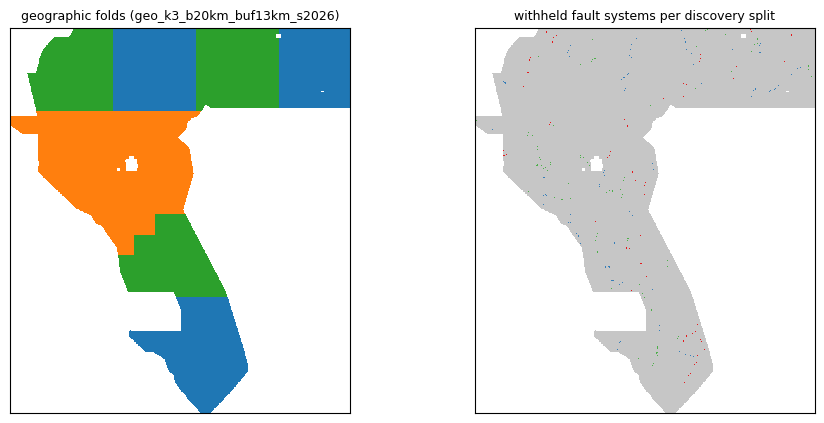

In [10]:
pipe.step('spatial_folds')
pipe.step('discovery_splits')
print(pipe.pc.fold_rel, '|', pipe.pc.discovery_rel)
from gems_bench.pipeline.status import fold_figure, save_fig
fig = fold_figure(pipe.pc)
if fig is not None:
    display(fig); save_fig(pipe.pc, fig, 'validation_design')

## 12. Feature store: create once, reuse

Families: raw 19-channel geophysics · Phase 2 engineered · Phase 1 `eda:*` maps · Phase 4 remote-sensing structural features (those the baselines use, or all) · Phase 5 fault-normal profiles · 1 m DEM aggregates. Only missing features are computed; each family is pushed to Drive as soon as it exists. `data/feature_store/pipeline_feature_registry.csv` declares name, source, transform, scale, support, CRS / grid, NoData behaviour, standardisation and a spec hash per feature.

In [11]:
pipe.step('feature_store')
reg = pathlib.Path('/content/gems_work/data/feature_store/pipeline_feature_registry.csv')
if reg.exists():
    fr = __import__('pandas').read_csv(reg)
    display(fr.groupby('family').agg(n=('name', 'size'), cached=('cached', 'sum')))

pipe.step('dem_pilot')                               # only runs when the DEM pilot is enabled

[feature_store] BLOCKED: missing prerequisite(s): segment_attributes (BLOCKED)
[feature_store] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)
[dem_pilot] BLOCKED: missing prerequisite(s): dem_inventory (BLOCKED), feature_store (BLOCKED)
[dem_pilot] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


StageResult(stage='dem_pilot', decision='BLOCKED', outcome='BLOCKED', validation='', reason='missing prerequisite(s): dem_inventory (BLOCKED), feature_store (BLOCKED)', recovery='see the traceback in the stage record; fix and re-run (completed work is kept)', seconds=0.0, summary={}, outputs=[])

## 13. Baselines: restore or train

G1 terrain LightGBM, G3 engineered LightGBM, RS05 (Phase 4), CNN-A and CNN-B (distance-aware), gated dual encoder, plus the label-free B0 lineament floor. A reported score is not a model: each baseline is `AVAILABLE` only if its finished run folder and maps are found and verified. Otherwise it is `NOT_AVAILABLE`, or it is retrained from the committed configuration snapshot when listed in `train_baselines`. Regenerated runs are labelled `historical_equivalence: false`.

In [12]:
pipe.step('baselines')
display(pipe.baselines())

[baselines] BLOCKED: missing prerequisite(s): feature_store (BLOCKED)
[baselines] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


,model,kind,gpu,cv_dir,origin,status,discovery,checkpoints,detail
0,B0_lineament,map,False,outputs/benchmark/experiments/b0_lineament_fus...,,NOT_AVAILABLE,n/a,False,no run folder
1,G1,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G1_s2026,,NOT_AVAILABLE,0/3,False,no run folder
2,G3,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G3_s2026,,NOT_AVAILABLE,0/3,False,no run folder
3,RS05_G3_noSS_RS,lgbm_rs,False,outputs/phase4/experiments/p4_RS05_G3_noSS_RS_...,,NOT_AVAILABLE,0/3,False,no run folder
4,CNN_A_dti,cnn3,True,outputs/phase3/experiments/p3_CNN_A_dti_p256_s...,,NOT_AVAILABLE,0/3,False,no run folder
5,DL00_CNN_B_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL00_CNN_B_dti_p...,,NOT_AVAILABLE,0/3,False,no run folder
6,DL02_CNN_TMGB_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL02_CNN_TMGB_dt...,,NOT_AVAILABLE,0/3,False,no run folder
7,P4_B_gated,cnn4,True,outputs/phase4/experiments/p4_P4_B_gated_p256_...,,NOT_AVAILABLE,0/3,False,no run folder


## 14–15. Research experiments: PU supervision, geometry-aware decoding, GeoStructureNet, multiscale structure

Each experiment has a hypothesis, a control, a fixed split version, resumable units (3 CV folds + 3 discovery splits), checkpoints synced to Drive at intervals, and the section-17 promotion gate. Order matters: `b0_reference` is the control of the others. GPU only; enable with `run_advanced_models=True`.

In [13]:
display(pipe.experiments())
pipe.step('advanced_models')

,experiment,group,control,resource,hypothesis,promotion,experiment_id,kind,prepare,train,evaluate,export,complete
0,b0_reference,B/C/E control,P4_B_gated,gpu,Re-training the gated dual encoder with the Ph...,section-17 promotion gate (configs/validation/...,b0_reference__d54e938a,cnn5,pending,pending,pending,pending,False
1,b1_bg_weight,B: PU supervision,P5_B0_gated,gpu,Down-weighting unlabeled pixels that carry str...,section-17 promotion gate (configs/validation/...,b1_bg_weight__7755635b,cnn5,pending,pending,pending,pending,False
2,b2_nnpu_p010,B: PU supervision,P5_B0_gated,gpu,nnPU with prior 1 % (central value of the swee...,section-17 promotion gate (configs/validation/...,b2_nnpu_p010__e0173a9a,cnn5,pending,pending,pending,pending,False
3,c1_geometry_heads,C: geometry,P5_B0_gated,gpu,Auxiliary distance-to-fault and axial-orientat...,section-17 promotion gate (configs/validation/...,c1_geometry_heads__9a77180d,cnn5,pending,pending,pending,pending,False
4,e1_gsn_parity,E: GeoStructureNet,P5_B0_gated,gpu,GeoStructureNet in parity configuration (gated...,section-17 promotion gate (configs/validation/...,e1_gsn_parity__b8b8c3db,cnn5,pending,pending,pending,pending,False


[advanced_models] BLOCKED: missing prerequisite(s): baselines (BLOCKED)
[advanced_models] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


StageResult(stage='advanced_models', decision='BLOCKED', outcome='BLOCKED', validation='', reason='missing prerequisite(s): baselines (BLOCKED)', recovery='see the traceback in the stage record; fix and re-run (completed work is kept)', seconds=0.0, summary={}, outputs=[])

## 16–17. Geographic and pseudo-discovery validation, model comparison and promotion

One protocol for every available model: geographic DTI (cross-fitted area budget) and pseudo-discovery DTI (withheld systems excluded / retained as FP) are reported **separately**; `public_lb` comes only from your manual `reports/leaderboard_log.csv`. Promotion to `promoted` is a manual, evidence-backed registry transition.

In [14]:
pipe.step('discovery_validation')
sb = pathlib.Path('/content/gems_work/reports/pipeline/scoreboard_latest.csv')
if sb.exists():
    b = __import__('pandas').read_csv(sb)
    display(b[[c for c in ('model', 'geo_dti_area', 'geo_fold_min', 'disc_dti_excl', 'disc_dti_retained_fp',
                           'short_recall_w', 'public_lb') if c in b.columns]])
from gems_bench.artifacts import ModelRegistry
display(ModelRegistry(pipe.pc.local / 'model_registry').table())
# Manual promotion (only when the candidate's promotion_decisions say promote=True):
# from gems_bench.experiment.promote import promote
# promote('<model_name>', '<experiment_id>'); pipe.push_all()

[discovery_validation] BLOCKED: missing prerequisite(s): baselines (BLOCKED)
[discovery_validation] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


,name,status,kind,experiment_id,oof,discovery,config_hash,git_commit,geo_dti,disc_dti_excl,disc_dti_retained_fp,protocol_hash,updated,notes


## 18. Ensemble optimisation

Members (≥ 2 with OOF + every discovery map) enter as per-fold rank quantiles; geographic weights are chosen on other folds, discovery weights with each split's withheld systems removed. An ensemble must pass the same gate against its best member.

In [15]:
pipe.step('ensemble')

[ensemble] BLOCKED: missing prerequisite(s): discovery_validation (BLOCKED)
[ensemble] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


StageResult(stage='ensemble', decision='BLOCKED', outcome='BLOCKED', validation='', reason='missing prerequisite(s): discovery_validation (BLOCKED)', recovery='see the traceback in the stage record; fix and re-run (completed work is kept)', seconds=0.0, summary={}, outputs=[])

## 19–20. Full-area inference and competition GeoTIFF

Uses the registry **champion** (status `promoted`): fold models averaged over the full footprint (chunked, Hann-blended tiles), area-budget export policy, one validated single-band float32 GeoTIFF per known-fault policy in `submissions/` with provenance JSON. **Uploading is manual**; record each upload in `reports/leaderboard_log.csv`.

In [16]:
pipe.step('full_inference')
pipe.step('submission')
import pandas as pd
from gems_bench.evaluation.scoreboard import LEADERBOARD_COLUMNS
log = pipe.pc.local / 'reports' / 'leaderboard_log.csv'
if not log.exists():
    pd.DataFrame(columns=LEADERBOARD_COLUMNS).to_csv(log, index=False)
display(pd.read_csv(log))

[full_inference] BLOCKED: missing prerequisite(s): feature_store (BLOCKED)
[full_inference] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)
[sync in] 0 copied (0.0 MiB), 0 unchanged, 0s: ['submissions', 'model_registry']
[submission] BLOCKED: missing prerequisite(s): full_inference (BLOCKED)
[submission] recovery: see the traceback in the stage record; fix and re-run (completed work is kept)


,submitted_at,model,submission_file,known_fault_policy,public_score,notes


## 21. Figures and research reporting

`reports/pipeline/` on Drive: `PIPELINE_REPORT.md`, `stage_status.csv`, `dashboard_summary.csv`, `baseline_status.csv`, `experiment_status.csv`, `scoreboard_latest.csv`, `figures/*.png|svg`. Per-experiment tables and figures stay in `experiments/<id>/`.

[sync out] 7 copied (0.2 MiB), 3 unchanged, 0s: ['reports/pipeline']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/reports.json']
[reports] DONE: reports: ok (1 checks)
[reports] outputs: ['/content/drive/MyDrive/GEMS_2/reports/pipeline']


,key,value
0,time,2026-10-22 13:40
1,mode,RESUME
2,device,CPU only
3,vram_gb,0.0
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,4
6,stages_cached,2
7,stages_pending,0
8,stages_failed,1
9,stages_blocked,10


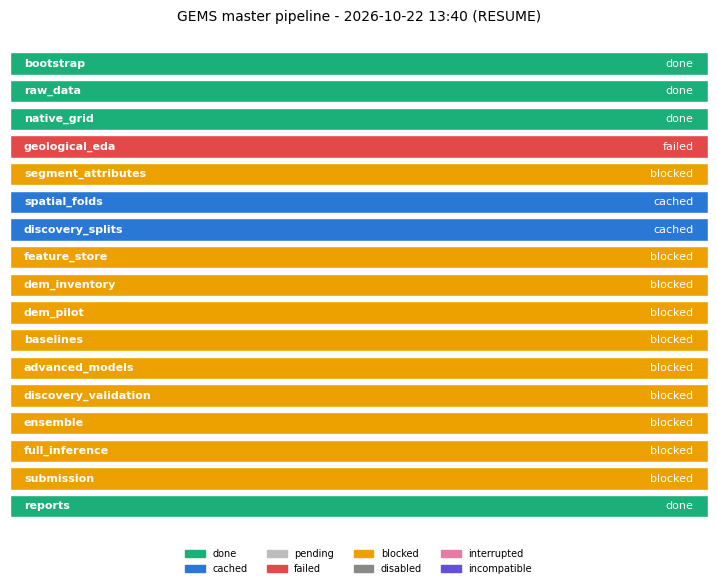

[sync out] 3 copied (0.1 MiB), 7 unchanged, 0s: ['reports/pipeline']


,key,value
0,time,2026-10-22 13:40
1,mode,RESUME
2,device,CPU only
3,vram_gb,0.0
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,4
6,stages_cached,2
7,stages_pending,0
8,stages_failed,1
9,stages_blocked,10


In [17]:
pipe.step('reports')
pipe.dashboard()

## 22. Final artifact and manifest validation

Re-validates every stage's outputs **on Drive** (what survives the session), lists the stage records and the latest events.

In [18]:
pipe.push_all()
final = pipe.plan(mode='FULL_PIPELINE', root='drive')
display(final[['stage', 'outputs', 'planned', 'last_status', 'last_origin', 'last_finished', 'detail']])
display(pipe.status())
display(pipe.events(30))
for s in ('feature_store', 'baselines', 'discovery_validation', 'submission'):
    print(s, '->', pipe.outputs(s)[:3])

[sync out] 10 copied (1.8 MiB), 34 unchanged, 0s: ['environment/pipeline', 'reports', 'environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv', 'data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv', 'environment/pipeline/native_grid.json', 'reports/pipeline/native_band_table.csv', 'outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026', 'outputs/benchmark/folds/discovery_d3_link1km_s2026', 'data/raw/dem_1m/tnm_urls.json', 'submissions', 'model_registry', 'reports/pipeline']


,stage,outputs,planned,last_status,last_origin,last_finished,detail
0,bootstrap,ok,SKIP_CACHED,done,built,2026-10-22T13:38:18,bootstrap: ok (3 checks)
1,raw_data,ok,SKIP_CACHED,done,built,2026-10-22T13:38:36,raw_data: ok (3 checks)
2,native_grid,ok,SKIP_CACHED,done,built,2026-10-22T13:40:01,native_grid: ok (1 checks)
3,geological_eda,missing,BUILD,failed,built,2026-10-22T13:40:01,eda_minimal: missing - known_fault_segments.pa...
4,segment_attributes,missing,BUILD,,,,native_segments: missing - native_segment_ids....
5,spatial_folds,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:02,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
6,discovery_splits,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:03,discovery:discovery_d3_link1km_s2026: ok (3 ch...
7,feature_store,missing,BUILD,,,,feature_store: missing - raw_mag_anom.npy: mis...
8,dem_inventory,missing,BUILD,,,,dem_inventory: missing - dem_inventory.csv: mi...
9,dem_pilot,missing,DISABLED (DEM pilot disabled (stages.run_dem_p...,,,,dem_pilot: missing - f1_dem_pilot__888c6e12:pr...


,stage,state,title,resource,origin,last_finished,attempts,reason,recovery,outputs
0,bootstrap,done,"Environment, Drive, workspace folders",light,built,2026-10-22T13:38:18,1,bootstrap: ok (3 checks),,"environment/pipeline/config_snapshot.json, rep..."
1,raw_data,done,"Competition files: locate, validate, download ...",network,built,2026-10-22T13:38:36,1,raw_data: ok (3 checks),,"data/raw/acquisition_manifest.json, reports/pi..."
2,native_grid,done,"Native 100 m grid, labels, template checks",cpu,built,2026-10-22T13:40:01,1,native_grid: ok (1 checks),,"environment/pipeline/native_grid.json, reports..."
3,geological_eda,failed,Phase-1 EDA dependency repair (minimal rebuild),cpu-heavy,built,2026-10-22T13:40:01,1,NameError: name 'version' is not defined,see the traceback in the stage record; fix and...,"outputs/eda/manifest.json, outputs/eda/datasets"
4,segment_attributes,blocked,Native-grid segment ids + attributes,cpu,,,0,missing prerequisite(s): geological_eda (FAILED),see the traceback in the stage record; fix and...,outputs/benchmark/datasets/native_segment_ids....
5,spatial_folds,cached,Geographic folds (Phase-2 protocol),cpu,adopted_existing,2026-10-22T13:40:02,1,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks),,outputs/benchmark/folds/geo_k3_b20km_buf13km_s...
6,discovery_splits,cached,Pseudo-discovery fault-system splits,cpu,adopted_existing,2026-10-22T13:40:03,1,discovery:discovery_d3_link1km_s2026: ok (3 ch...,,outputs/benchmark/folds/discovery_d3_link1km_s...
7,feature_store,blocked,"Feature store: compute once, reuse",cpu-heavy,,,0,missing prerequisite(s): segment_attributes (B...,see the traceback in the stage record; fix and...,outputs/benchmark/cache/features/raw_mag_anom....
8,dem_inventory,blocked,USGS 1 m DEM inventory (metadata only),light,,,0,missing prerequisite(s): native_grid (not run),,"data/raw/dem_1m/inventory, data/raw/dem_1m/tnm..."
9,dem_pilot,blocked,"1 m DEM pilot: selection, download, morphology...",network-heavy,,,0,missing prerequisite(s): dem_inventory (BLOCKE...,see the traceback in the stage record; fix and...,"experiments/f1_dem_pilot__888c6e12, data/proce..."


,time,stage,event,decision,validation,seconds,reason
0,2026-10-22T13:38:12,bootstrap,start,RUN,ok,NaN,NaN
1,2026-10-22T13:38:18,bootstrap,done,NaN,NaN,6.7,NaN
2,2026-10-22T13:38:24,raw_data,start,BUILD,missing,NaN,NaN
3,2026-10-22T13:38:36,raw_data,done,NaN,NaN,12.3,NaN
4,2026-10-22T13:38:36,native_grid,start,BUILD,missing,NaN,NaN
5,2026-10-22T13:40:01,native_grid,done,NaN,NaN,84.2,NaN
6,2026-10-22T13:40:01,geological_eda,start,BUILD,missing,NaN,NaN
7,2026-10-22T13:40:01,geological_eda,failed,NaN,NaN,NaN,NameError: name 'version' is not defined
8,2026-10-22T13:40:06,reports,start,RUN,missing,NaN,NaN
9,2026-10-22T13:40:09,reports,done,NaN,NaN,2.5,NaN


feature_store -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_mag_anom.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_rtp.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_tmi_hg.npy']
baselines -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/b0_lineament_fused_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/lgbm_G1_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/disc0_lgbm_G1_s2026']
discovery_validation -> []
submission -> ['/content/drive/MyDrive/GEMS_2/experiments/z_submission__c46ee057', '/content/drive/MyDrive/GEMS_2/submissions', '/content/drive/MyDrive/GEMS_2/model_registry']


## 23. Resume instructions

After a disconnect or in a new session: **run sections 1–4 again, then the same cells (or `pipe.run()`)**.

* Finished stages are `SKIP_CACHED` (validated on Drive, staged back to `/content/gems_work` only when needed).
* Interrupted feature builds continue with the missing features; interrupted experiments continue at the next CV fold / discovery split and resume training from the last checkpoint pushed to Drive (`ckpt_sync_min`).
* `pipe.status()` shows the last state of every stage; `pipe.record('<stage>')` the full record (error, traceback tail, recovery action, code commit, fingerprints).
* To change a protocol (folds, features, experiment settings) edit the configuration: a new versioned folder / experiment id is created; earlier results are kept.
* On short sessions set `max_stage_minutes` (e.g. 200): training stops cleanly at an epoch boundary and resumes next time.

The original notebooks `00`–`07` remain as focused research entry points; this notebook is the recommended start.